# K-Means Clustering on Congress Votes

**Objective:** Cluster senators from voting records to explore unsupervised grouping patterns.

**Dataset used:** `data/114_congress.csv`

**Main techniques used:** Exploratory analysis, Euclidean distance, K-Means clustering, cluster interpretation, visualization


## Dataset Overview

This notebook introduces K-Means clustering on voting records from the 114th U.S. Congress.


In [17]:
import pandas as pd

votes = pd.read_csv('data/114_congress.csv')
print(votes.head())


        name party state  00001  00004  00005  00006  00007  00008  00009  \
0  Alexander     R    TN    0.0    1.0    1.0    1.0    1.0    0.0    0.0   
1     Ayotte     R    NH    0.0    1.0    1.0    1.0    1.0    0.0    0.0   
2    Baldwin     D    WI    1.0    0.0    0.0    1.0    0.0    1.0    0.0   
3   Barrasso     R    WY    0.0    1.0    1.0    1.0    1.0    0.0    1.0   
4     Bennet     D    CO    0.0    0.0    0.0    1.0    0.0    1.0    0.0   

   00010  00020  00026  00032  00038  00039  00044  00047  
0    1.0    1.0    1.0    0.0    0.0    0.0    0.0    0.0  
1    1.0    0.0    1.0    0.0    1.0    0.0    1.0    0.0  
2    1.0    0.0    0.0    1.0    1.0    0.0    1.0    1.0  
3    1.0    1.0    1.0    0.0    0.0    1.0    0.0    0.0  
4    1.0    0.0    0.0    0.0    1.0    0.0    1.0    0.0  


## Explore the Dataset

Start by checking party counts and average voting behavior before running the clustering algorithm.


In [18]:
print(votes['party'].value_counts())
print(votes.mean(numeric_only=True))


party
R    54
D    44
I     2
Name: count, dtype: int64
00001    0.325
00004    0.575
00005    0.535
00006    0.945
00007    0.545
00008    0.415
00009    0.545
00010    0.985
00020    0.525
00026    0.545
00032    0.410
00038    0.480
00039    0.510
00044    0.460
00047    0.370
dtype: float64


## Euclidean Distance

Before fitting K-Means, the notebook measures similarity between senators with Euclidean distance.


Smaller Euclidean distances indicate more similar voting behavior between senators.

![Euclidean distance](<attachment:distance euclidienne.png>)

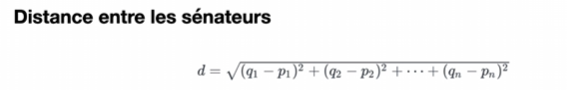

In [19]:
from sklearn.metrics.pairwise import euclidean_distances
print(euclidean_distances(votes.iloc[0, 3:].values.reshape(1, -1), votes.iloc[1, 3:].values.reshape(1, -1)))


[[1.73205081]]


In [20]:
distances = euclidean_distances(votes.iloc[0, 3:].values.reshape(1, -1) , votes.iloc[
    2,3:].values.reshape(1,- 1))
print(distances)



[[3.31662479]]


In [21]:
from sklearn.cluster import KMeans
kmeans_model = KMeans(n_clusters=2, random_state=1)
senator_distances = kmeans_model.fit_transform(votes.iloc[:, 3:])
print(senator_distances)
 


[[3.05549495 1.32795748]
 [2.55656985 2.08889231]
 [0.39783364 3.47194184]
 [3.34704587 0.19025863]
 [1.39938258 3.02411793]
 [0.39783364 3.47194184]
 [3.34704587 0.19025863]
 [0.39783364 3.47194184]
 [3.34704587 0.19025863]
 [0.34551804 3.36355037]
 [0.39783364 3.47194184]
 [3.19764574 0.98156562]
 [0.39783364 3.47194184]
 [3.27743878 0.52640995]
 [0.39783364 3.47194184]
 [1.15587602 3.18231165]
 [1.21218097 3.19087024]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [2.55656985 2.08889231]
 [0.61232203 3.36760208]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [3.49005642 0.92432687]
 [3.34704587 0.19025863]
 [1.6873531  2.87936517]
 [0.39783364 3.47194184]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [0.39783364 3.47194184]
 [3.34704587 0.19025863]
 [3.34704587 0.19025863]
 [0.61232203 3.36760208]
 [3.19764574 0.93411026]
 [0.39783364 3.47194184]
 [3.12204428 0.66729997]
 [3.34704587 0.19025863]


## First Clustering Pass

The model groups senators into two clusters and compares the resulting labels with party affiliation.


In [22]:
#exploer des cluster avec crosstab
kmeans_model = KMeans(n_clusters=2, random_state=1)
senator_distances = kmeans_model.fit_transform(votes.iloc[:, 3:])
labeles = kmeans_model.labels_
print(pd.crosstab(labeles, votes['party']))


party   D  I   R
row_0           
0      43  2   0
1       1  0  54


In [23]:
votes[ (labeles == 0) & (votes['party'] == 'D') ]
 


In [24]:
democratic_outliers = votes[ (labeles == 1) & (votes['party'] == 'D') ]
print(democratic_outliers)


       name party state  00001  00004  00005  00006  00007  00008  00009  \
56  Manchin     D    WV    0.0    1.0    0.0    1.0    0.0    0.0    1.0   

    00010  00020  00026  00032  00038  00039  00044  00047  
56    1.0    1.0    0.0    0.0    1.0    1.0    0.0    0.0  


## Visualize the Clusters

The scatter plot displays the cluster assignments produced by the K-Means model.


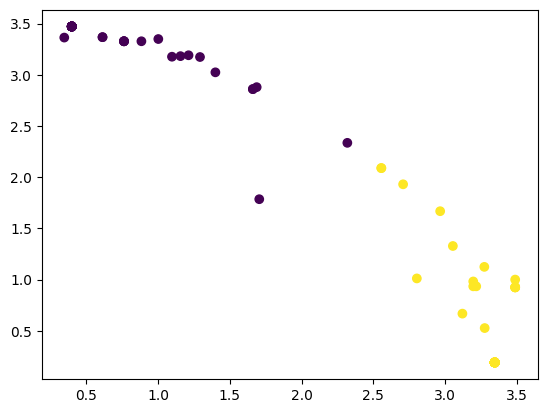

In [25]:
import matplotlib.pyplot as plt
plt.scatter(x=senator_distances[:, 0],y= senator_distances[:, 1], c=labeles)
plt.show()


## Centroid Interpretation

K-Means starts from initial centroids and iteratively refines them based on the points assigned to each group.


## Identify the Most Distinct Senators

The final step creates an extremism score from cluster distances to highlight senators who are farthest from the center of their group.


In [26]:
extremism = (senator_distances ** 3).sum(axis=1)
votes['extremism'] = extremism

votes = votes.sort_values('extremism', ascending=False)

votes.head(10)


## Conclusion

**What was done:** Explored congressional voting data, applied K-Means clustering, and interpreted the resulting groups.

**What was learned:** Unsupervised clustering can reveal meaningful structure even without target labels.

**Possible improvements:** Test different numbers of clusters and compare with dimensionality reduction methods.
